In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math


from astro_tools.calculations import rkf45
from astro_tools.data import EARTH, MOON

In [16]:
# abolute tolerances
atol = np.array([
    1e-3,   # Position (m)
    1e-6    # Velocity (m/s)
])

# relative tolerances 
rtol = 1e-8

Generating a rectilinear trajectory out and back from Earth

In [20]:
y0 = np.array([
    6_500_000,          # x position [m]
    7_800              # x velocity [m/s]
])

tspan = (0, 70 * 60)

def derivatives(t: float, f: np.ndarray) -> np.ndarray:
     rates = np.array([
        f[1],
        -EARTH.mu / f[0]**2
     ])
     return rates

t_rectilinear, y_rectilinear = rkf45(y0, tspan, derivatives, rtol, atol)

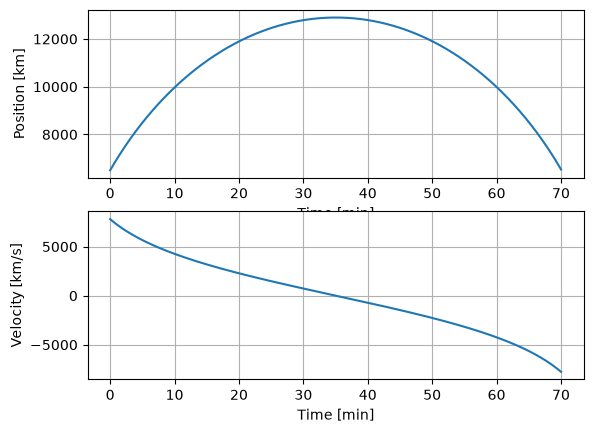

In [ ]:
fig, axs = plt.subplots(2, 1)

axs[0].set_xlabel("Time [min]")
axs[0].set_ylabel("Position [km]")
axs[0].plot(t_rectilinear/60, y_rectilinear[:, 0]/ 1000)
axs[0].grid(True)

axs[1].set_xlabel("Time [min]")
axs[1].set_ylabel("Velocity [km/s]")
axs[1].plot(t_rectilinear/60, y_rectilinear[:, 1])
axs[1].grid(True)

Translunar trajectory

In [ ]:
deg2rad = math.pi / 180
days = 60 * 60 * 24

# given
d0 = 200_000        # meters
phi = -90 * deg2rad
gamma = 20 * deg2rad
v_bo = 10_914.8 # mk/s
tf = 3.16689 * days

# calculate 
M = EARTH.mass + MOON.mass
pi_1 = EARTH.mass / M
pi_2 = MOON.mass / M
mu = EARTH.mu + MOON.mu

r0 = d0 + EARTH.radius
x = r0*math.cos(phi) + x1
y = r0*math.sin(phi)

vx = v_bo * (math.sin(gamma)*math.cos(phi) - math.cos(gamma)*math.sin(phi))
vy = v_bo * (math.sin(gamma)*math.sin(phi) + math.cos(gamma)*math.cos(phi))

y0 = np.array([
    x,
    y,
    vx,
    vy
])